### **Clase Practica: Distribuciones**

In [ ]:
# Librerias usadas 
import pandas as pd 
import openpyxl
import numpy as np
# para prueba jacque bera
from statsmodels.stats.stattools import jarque_bera
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
# Cargue de la base de datos original
df_acciones = pd.read_excel("Material_practico_2026-II.xlsx")
df_acciones

# Combertir JP Morgan a pesos Colombianos
df_acciones['J.P. Morgan Chase (COP)'] = round(df_acciones['J.P. Morgan Chase (USD)']*df_acciones['TRM (COP)'],0)
df_acciones

,Fecha,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP)
0,2015-01-02,16600.0,39.69,2284.22,90661.0
1,2015-01-03,17000.0,40.19,2284.22,91803.0
2,2015-01-04,16700.0,39.62,2282.27,90424.0
3,2015-01-05,17000.0,39.74,2282.13,90692.0
4,2015-01-06,16900.0,40.02,2279.99,91245.0
...,...,...,...,...,...
2469,2025-12-14,26900.0,84.76,2982.29,252779.0
2470,2025-12-15,27800.0,84.73,2964.56,251187.0
2471,2025-12-19,27240.0,84.94,2997.20,254582.0
2472,2025-12-27,26920.0,87.05,2996.60,260854.0


In [3]:
# Calculo de los rendimientos 
df_rendimiento = df_acciones.set_index('Fecha').sort_index()

# Calcular (dato_actual - dato_anterior) / dato_anterior para todas las columnas
columnas_precios = ['Bancolombia (P) (COP)', 'J.P. Morgan Chase (USD)', 'TRM (COP)', 'J.P. Morgan Chase (COP)']

for col in columnas_precios:
    df_rendimiento[f'Rend_{col}'] = np.log(df_rendimiento[col] / df_rendimiento[col].shift(1)).round(4) #np.log(df_rendimiento[col].pct_change().round(4))


df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP)
Fecha,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061
...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134


### **Construcción del portafolio**

In [4]:
# Cantidad de dinero a invertir en cada acción
Cantidad_Banc = 1200
Cantidad_JP = 1000
Cantidad_TRM = 20000

# Precio de las acciones en la ultima fecha de cierre de la base de datos

precio_banc , precio_JP, precio_TRM = df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['Bancolombia (P) (COP)'].iloc[0],\
df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['J.P. Morgan Chase (COP)'].iloc[0],\
    df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['TRM (COP)'].iloc[0]

# Pesos del portafolio 
w_banc = Cantidad_Banc*precio_banc
w_JP = Cantidad_JP*precio_JP
w_TRM = Cantidad_TRM*precio_TRM

portafolio = w_banc + w_JP + w_TRM

# % de pesos del portafolio
w_banc_prop = w_banc / portafolio *100
w_JP_prop = w_JP / portafolio *100
w_TRM_prop = w_TRM / portafolio *100

df_rendimiento.shape

(2474, 8)

In [5]:
print("Precio Bancolombia: ", precio_banc,"precio_JP: ", precio_JP, "precio_TRM: ", precio_TRM)
print("Pesos Bancolombia: ", w_banc,"Pesos JP: ", w_JP, "Pesos TRM: ", w_TRM)
print("pesos%% de Bancolombia: ", w_banc_prop,"pesos%% JP: ", w_JP_prop, "pesos%% TRM: ", w_TRM_prop)

Precio Bancolombia:  27460.0 precio_JP:  260764.0 precio_TRM:  2992.81
Pesos Bancolombia:  32952000.0 Pesos JP:  260764000.0 Pesos TRM:  59856200.0
pesos%% de Bancolombia:  9.319737241785411 pesos%% JP:  73.75127343156504 pesos%% TRM:  16.92898932664955


In [6]:
# Calculo del rendimeinto del portafolio
cols_rend = ['Rend_Bancolombia (P) (COP)', 'Rend_J.P. Morgan Chase (COP)','Rend_TRM (COP)']
pesos = [w_banc_prop, w_JP_prop, w_TRM_prop]

df_rendimiento['Rend_Portafolio'] = df_rendimiento[cols_rend].dot(pesos)/100
df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio
Fecha,,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125,0.011437
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151,-0.012948
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030,0.003855
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061,0.003797
...,...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836


In [7]:
### prueba de normalaidad jarque bera

jarque_bera(df_rendimiento['Rend_Portafolio'].dropna())
print("p-value: ", jarque_bera(df_rendimiento['Rend_Portafolio'].dropna())[1])
print("Estadistico: ", jarque_bera(df_rendimiento['Rend_Portafolio'].dropna())[0])
print("Valor crítico: ", 5.99)

# P-value < 0.05, por lo tanto se rechaza la hipótesis nula de normalidad.

p-value:  0.0
Estadistico:  14787.03794437744
Valor crítico:  5.99


<Axes: title={'center': 'Rendimientos Diarios - Bancolombia'}, xlabel='Fecha'>

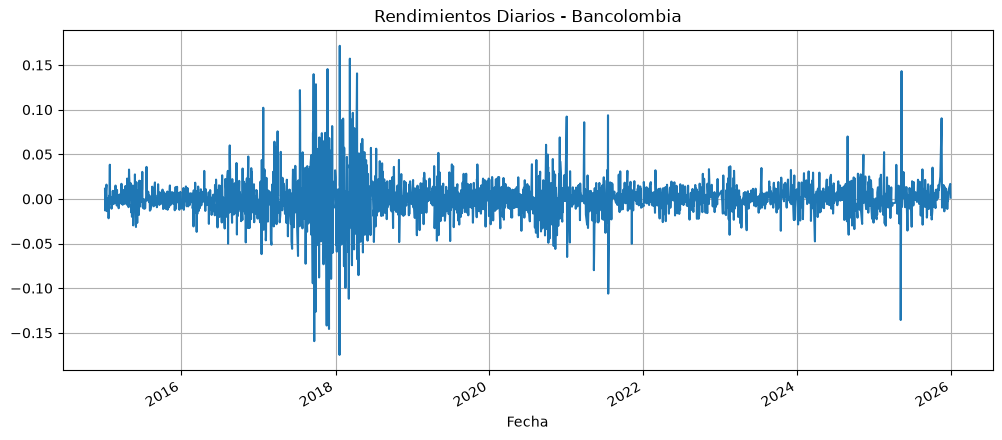

In [8]:
### Grafico de los rendimientos del portafolio

df_rendimiento['Rend_Portafolio'].plot(figsize=(12, 5), title='Rendimientos Diarios - Bancolombia', grid=True)

In [9]:
## Calculo de volatilidad historica del portafolio
volatilidad = np.std(df_rendimiento['Rend_Portafolio'].dropna())
promedio = np.mean(df_rendimiento['Rend_Portafolio'].dropna())
n_con = 0.95
z = norm.interval(n_con)


In [10]:
print("volatilidad historica del portafolio: ", volatilidad*100)
print("promedio historico del portafolio: ", promedio*100)
print("Z: ", z[1])

volatilidad historica del portafolio:  2.26375301783404
promedio historico del portafolio:  0.03536168068114118
Z:  1.959963984540054


In [11]:
df_rendimiento['lin_inf'] = promedio - z[1]*volatilidad
df_rendimiento['lin_sup'] = promedio + z[1]*volatilidad
df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio,lin_inf,lin_sup
Fecha,,,,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN,NaN,-0.044015,0.044722
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125,0.011437,-0.044015,0.044722
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151,-0.012948,-0.044015,0.044722
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030,0.003855,-0.044015,0.044722
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061,0.003797,-0.044015,0.044722
...,...,...,...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628,-0.044015,0.044722
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596,-0.044015,0.044722
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836,-0.044015,0.044722


Text(0.5, 1.0, 'Rendimientos Diarios del Portafolio con Intervalos de Confianza')

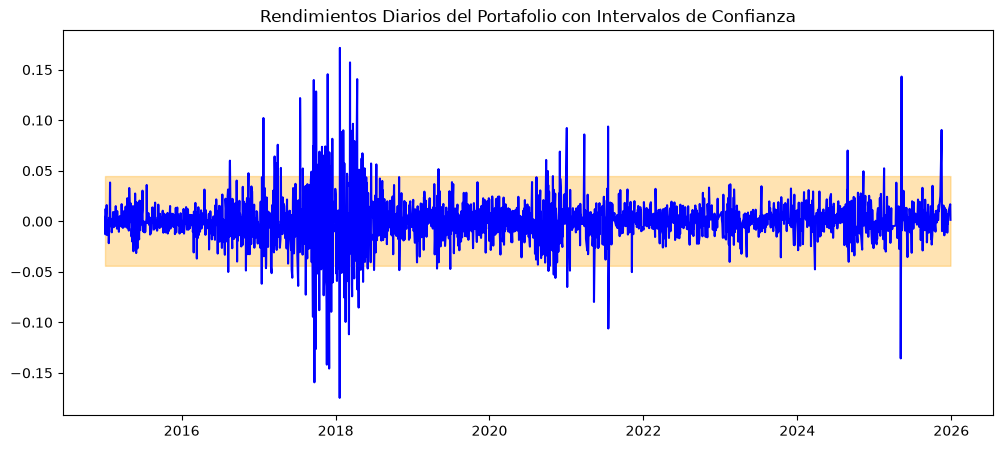

In [12]:
## Grafica de rendimientos del portafolio con intervalos de confianza
plt.figure(figsize=(12, 5))
plt.plot(df_rendimiento['Rend_Portafolio'], label='Rendimientos del Portafolio', color='blue')
plt.fill_between(df_rendimiento.index, df_rendimiento['lin_inf'], df_rendimiento['lin_sup'], color='orange', alpha=0.3, label='Intervalo de Confianza 95%')
plt.title('Rendimientos Diarios del Portafolio con Intervalos de Confianza')

### **Rentabilidad promedios moviles**

In [13]:
### Volatilidad promedios moviles 

df_rendimiento['MA22_Rend'] = df_rendimiento['Rend_Portafolio'].rolling(window=22).mean().shift(1)
df_rendimiento['vola_MA22_Rend'] = df_rendimiento['Rend_Portafolio'].rolling(window=22).std().shift(1)
df_rendimiento['lin_inf_MA22'] = df_rendimiento['MA22_Rend'] - z[1]*df_rendimiento['vola_MA22_Rend']
df_rendimiento['lin_sup_MA22'] = df_rendimiento['MA22_Rend'] + z[1]*df_rendimiento['vola_MA22_Rend']


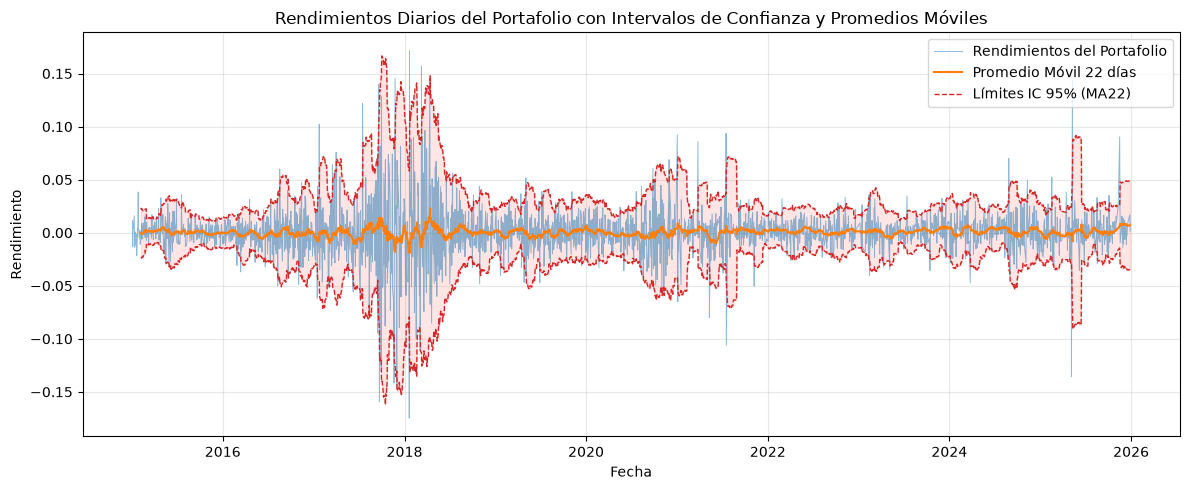

In [14]:
plt.figure(figsize=(12, 5))

# 1. Serie de rendimientos (con alpha=0.5 y línea más fina para no tapar el promedio ni las bandas)
plt.plot(df_rendimiento.index, df_rendimiento['Rend_Portafolio'], 
         label='Rendimientos del Portafolio', color='#1f77b4', linewidth=0.7, alpha=0.5)

# 2. Promedio Móvil 22 días
plt.plot(df_rendimiento.index, df_rendimiento['MA22_Rend'], 
         label='Promedio Móvil 22 días', color='#ff7f0e', linewidth=1.5)

# 3. Líneas de los límites superior e inferior (en rojo punteado para que se vean exactos como en Excel)
plt.plot(df_rendimiento.index, df_rendimiento['lin_sup_MA22'], 
         color='#d62728', linestyle='--', linewidth=1, label='Límites IC 95% (MA22)')
plt.plot(df_rendimiento.index, df_rendimiento['lin_inf_MA22'], 
         color='#d62728', linestyle='--', linewidth=1)

# 4. Sombreado entre los límites
plt.fill_between(df_rendimiento.index, df_rendimiento['lin_inf_MA22'], df_rendimiento['lin_sup_MA22'], 
                 color='#ff9896', alpha=0.25)

plt.title('Rendimientos Diarios del Portafolio con Intervalos de Confianza y Promedios Móviles')
plt.xlabel('Fecha')
plt.ylabel('Rendimiento')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **Rentabilidad para un periodo de tiempo t: Clase 2 Virtual**


In [22]:
# Rentabilidad para un periodo de tiempo t

df_acciones = pd.read_excel("Material_practico_2026-II.xlsx")
df_acciones

# Combertir JP Morgan a pesos Colombianos
df_acciones['J.P. Morgan Chase (COP)'] = round(df_acciones['J.P. Morgan Chase (USD)']*df_acciones['TRM (COP)'],0)
df_acciones


# Calcular (dato_actual - dato_anterior) / dato_anterior para todas las columnas
# Calculo de los rendimientos 

df_rendimiento = df_acciones.set_index('Fecha').sort_index()

# Calcular (dato_actual - dato_anterior) / dato_anterior para todas las columnas
columnas_precios = ['Bancolombia (P) (COP)', 'J.P. Morgan Chase (USD)', 'TRM (COP)', 'J.P. Morgan Chase (COP)']

for col in columnas_precios:
    df_rendimiento[f'Rend_{col}'] = np.log(df_rendimiento[col] / df_rendimiento[col].shift(1)).round(4) #np.log(df_rendimiento[col].pct_change().round(4))


df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP)
Fecha,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061
...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134


In [23]:
# Cantidad de dinero a invertir en cada acción
Cantidad_Banc = 1200
Cantidad_JP = 1000
Cantidad_TRM = 20000

# Precio de las acciones en la ultima fecha de cierre de la base de datos

precio_banc , precio_JP, precio_TRM = df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['Bancolombia (P) (COP)'].iloc[0],\
df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['J.P. Morgan Chase (COP)'].iloc[0],\
    df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['TRM (COP)'].iloc[0]

# Pesos del portafolio 
w_banc = Cantidad_Banc*precio_banc
w_JP = Cantidad_JP*precio_JP
w_TRM = Cantidad_TRM*precio_TRM

portafolio = w_banc + w_JP + w_TRM

# % de pesos del portafolio
w_banc_prop = w_banc / portafolio *100
w_JP_prop = w_JP / portafolio *100
w_TRM_prop = w_TRM / portafolio *100

df_rendimiento.shape

(2474, 8)

In [24]:
print("Precio Bancolombia: ", precio_banc,"precio_JP: ", precio_JP, "precio_TRM: ", precio_TRM)
print("Pesos Bancolombia: ", w_banc,"Pesos JP: ", w_JP, "Pesos TRM: ", w_TRM)
print("pesos%% de Bancolombia: ", w_banc_prop,"pesos%% JP: ", w_JP_prop, "pesos%% TRM: ", w_TRM_prop)

Precio Bancolombia:  27460.0 precio_JP:  260764.0 precio_TRM:  2992.81
Pesos Bancolombia:  32952000.0 Pesos JP:  260764000.0 Pesos TRM:  59856200.0
pesos%% de Bancolombia:  9.319737241785411 pesos%% JP:  73.75127343156504 pesos%% TRM:  16.92898932664955


In [25]:
# Calculo del rendimeinto del portafolio
cols_rend = ['Rend_Bancolombia (P) (COP)', 'Rend_J.P. Morgan Chase (COP)','Rend_TRM (COP)']
pesos = [w_banc_prop, w_JP_prop, w_TRM_prop]

df_rendimiento['Rend_Portafolio'] = df_rendimiento[cols_rend].dot(pesos)/100
df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio
Fecha,,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125,0.011437
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151,-0.012948
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030,0.003855
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061,0.003797
...,...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836


In [29]:
# Calcular (dato_actual - dato_anterior) / dato_anterior para todas las columnas
columnas_precios = ['Bancolombia (P) (COP)', 'J.P. Morgan Chase (USD)', 'TRM (COP)', 'J.P. Morgan Chase (COP)']
df_rendimiento_20 = df_rendimiento.copy()

for col in columnas_precios:
    df_rendimiento_20[f'Rend_20{col}'] = np.log(df_rendimiento_20[col] / df_rendimiento_20[col].shift(19)).round(4) #np.log(df_rendimiento[col].pct_change().round(4))


df_rendimiento_20

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio,Rend_20Bancolombia (P) (COP),Rend_20J.P. Morgan Chase (USD),Rend_20TRM (COP),Rend_20J.P. Morgan Chase (COP)
Fecha,,,,,,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125,0.011437,NaN,NaN,NaN,NaN
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151,-0.012948,NaN,NaN,NaN,NaN
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030,0.003855,NaN,NaN,NaN,NaN
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061,0.003797,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628,-0.0772,0.2062,-0.0148,0.1914
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596,-0.0443,0.2100,-0.0351,0.1749
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836,-0.0102,0.1481,-0.0050,0.1431


In [30]:
# Calculo del rendimeinto del portafolio a 20 dias 
cols_rend = ['Rend_20Bancolombia (P) (COP)', 'Rend_20J.P. Morgan Chase (COP)','Rend_20TRM (COP)']
pesos = [w_banc_prop, w_JP_prop, w_TRM_prop]

df_rendimiento_20['Rend20_Portafolio'] = df_rendimiento_20[cols_rend].dot(pesos)/100
df_rendimiento_20

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio,Rend_20Bancolombia (P) (COP),Rend_20J.P. Morgan Chase (USD),Rend_20TRM (COP),Rend_20J.P. Morgan Chase (COP),Rend20_Portafolio
Fecha,,,,,,,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125,0.011437,NaN,NaN,NaN,NaN,NaN
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151,-0.012948,NaN,NaN,NaN,NaN,NaN
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030,0.003855,NaN,NaN,NaN,NaN,NaN
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061,0.003797,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628,-0.0772,0.2062,-0.0148,0.1914,0.131460
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596,-0.0443,0.2100,-0.0351,0.1749,0.118920
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836,-0.0102,0.1481,-0.0050,0.1431,0.103741


In [31]:
# Teorico

Rentabilidad_diaria = np.mean(df_rendimiento_20['Rend_Portafolio'].dropna())
volatiliad_diaria = np.std(df_rendimiento_20['Rend_Portafolio'].dropna())
rentabilidad = Rentabilidad_diaria * 20
volatilidad = volatiliad_diaria * np.sqrt(20)
varianza = volatilidad**2

In [42]:
# Real

rentabilidad_real = np.mean(df_rendimiento_20['Rend20_Portafolio'].dropna())
volatilidad_real = np.std(df_rendimiento_20['Rend20_Portafolio'].dropna())
varianza_real = volatilidad_real**2

In [ ]:

print("Teorico")
print("Rentabilidad diaria: ", Rentabilidad_diaria)
print("Volatilidad diaria: ", volatiliad_diaria*100)
print("")
print("Rentabilidad para 20 días: ", rentabilidad*100)
print("Volatilidad para 20 días: ", volatilidad*100)
print("Varianza para 20 días: ", varianza*100)

print("")
print("Real")
print("Rentabilidad diaria: ", rentabilidad_real*100)   
print("Volatilidad diaria: ", volatilidad_real*100)
print("Varianza diaria: ", varianza_real*100)

# EL rendimiento teorico es mayor que el rendimiento real, mientras que la volatilidad y varianza teorica es menor que la volatilidad
#  y varianza real. Esto indica que el portafolio tiene un mayor riesgo de lo esperado y un menor rendimiento de lo esperado.

Teorico
Rentabilidad diaria:  0.0003536168068114118
Volatilidad diaria:  2.26375301783404

Rentabilidad para 20 días:  0.7072336136228236
Volatilidad para 20 días:  10.123811264294414
Varianza para 20 días:  1.0249155451505445

Real
Rentabilidad diaria:  0.6567491652594898
Volatilidad diaria:  7.170828048123617
Varianza diaria:  0.5142077489575637


### **Tecnicas de pronostico: Paseo Aleatorio**

In [49]:
df_rendimiento.tail(10)

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio
Fecha,,,,,,,,,
2025-12-06,26860.0,83.26,3049.47,253899.0,0.0015,0.0201,-0.0038,0.0164,0.011592
2025-12-07,26820.0,83.69,3015.47,252365.0,-0.0015,0.0052,-0.0112,-0.0061,-0.006535
2025-12-09,26980.0,85.12,2989.71,254484.0,0.0059,0.0169,-0.0086,0.0084,0.005289
2025-12-12,27000.0,85.49,3002.80,256709.0,0.0007,0.0043,0.0044,0.0087,0.007226
2025-12-13,27300.0,84.73,2984.02,252836.0,0.0110,-0.0089,-0.0063,-0.0152,-0.011252
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836
2025-12-27,26920.0,87.05,2996.60,260854.0,-0.0118,0.0245,-0.0002,0.0243,0.016788


In [53]:
Volatilidad_banc = np.std(df_rendimiento['Rend_Bancolombia (P) (COP)'].dropna())
promedio_banc = np.mean(df_rendimiento['Rend_Bancolombia (P) (COP)'].dropna())
volatilidad_JP = np.std(df_rendimiento['Rend_J.P. Morgan Chase (COP)'].dropna())
promedio_JP = np.mean(df_rendimiento['Rend_J.P. Morgan Chase (COP)'].dropna())
volatilidad_TRM = np.std(df_rendimiento['Rend_TRM (COP)'].dropna())
promedio_TRM = np.mean(df_rendimiento['Rend_TRM (COP)'].dropna())


In [56]:
print("Volatilidad_bancolombia: ", Volatilidad_banc)
print("Promedio_bancolombia: ", promedio_banc)
print("Volatilidad_JP: ", volatilidad_JP)
print("Promedio_JP: ", promedio_JP)
print("Volatilidad_TRM: ", volatilidad_TRM)
print("Promedio_TRM: ", promedio_TRM)

Volatilidad_bancolombia:  0.017572728093377663
Promedio_bancolombia:  0.00020279013344116461
Volatilidad_JP:  0.029472010574920382
Promedio_JP:  0.00042883137889203386
Volatilidad_TRM:  0.009515973348607364
Promedio_TRM:  0.00010897695107157301


In [64]:
# Proyecciones a un año 252

# 1. Extraer el último precio real de cada una de las 3 series
ultimo_precio_banc = df_rendimiento['Bancolombia (P) (COP)'].iloc[-1]
ultimo_precio_jp   = df_rendimiento['J.P. Morgan Chase (COP)'].iloc[-1]
ultimo_precio_trm  = df_rendimiento['TRM (COP)'].iloc[-1]

# 2. Definir horizonte de proyección (252 días bursátiles)
dias = 252
# np.random.seed(42)  # Descomenta si quieres fijar la semilla aleatoria

# 3. Generar valores aleatorios entre 0 y 1 independientes para cada serie (=ALEATORIO())
aleatorios_banc = np.random.uniform(0, 1, size=dias)
aleatorios_jp   = np.random.uniform(0, 1, size=dias)
aleatorios_trm  = np.random.uniform(0, 1, size=dias)

# 4. Calcular el choque normal N(0, volatilidad) para cada serie (=INV.NORM(ALEATORIO(); 0; desv))
shock_banc = norm.ppf(aleatorios_banc, loc=0, scale=Volatilidad_banc)
shock_jp   = norm.ppf(aleatorios_jp,   loc=0, scale=volatilidad_JP)
shock_trm  = norm.ppf(aleatorios_trm,  loc=0, scale=volatilidad_TRM)

# 5. Ciclo día a día para construir las 3 trayectorias (igual a arrastrar en Excel)
proy_banc = [ultimo_precio_banc]
proy_jp   = [ultimo_precio_jp]
proy_trm  = [ultimo_precio_trm]

for i in range(dias):
    # Bancolombia (P) (COP)
    proy_banc.append(proy_banc[-1] * np.exp(promedio_banc + shock_banc[i]))
    
    # J.P. Morgan Chase (COP)
    proy_jp.append(proy_jp[-1] * np.exp(promedio_JP + shock_jp[i]))
    
    # TRM (COP)
    proy_trm.append(proy_trm[-1] * np.exp(promedio_TRM + shock_trm[i]))

# Quitamos el primer elemento (que era el último precio histórico) para dejar exactamente los 252 días proyectados
proy_banc = proy_banc[1:]
proy_jp   = proy_jp[1:]
proy_trm  = proy_trm[1:]

# 6. Armar el DataFrame de proyecciones con fechas futuras hábiles
fechas_futuras = pd.bdate_range(start=df_rendimiento.index[-1] + pd.Timedelta(days=1), periods=dias)

df_proyecciones = pd.DataFrame({
    'Proy_Bancolombia (P) (COP)': proy_banc,
    'Proy_J.P. Morgan Chase (COP)': proy_jp,
    'Proy_TRM (COP)': proy_trm
}, index=fechas_futuras)

df_proyecciones

,Proy_Bancolombia (P) (COP),Proy_J.P. Morgan Chase (COP),Proy_TRM (COP)
2025-12-29,27461.876252,270536.025433,3004.707753
2025-12-30,27709.671006,266271.629820,3031.237531
2025-12-31,27160.756495,241478.057004,3031.690010
2026-01-01,27693.257351,242374.756833,3060.545480
2026-01-02,27708.835876,233370.847869,3070.679299
...,...,...,...
2026-12-09,34945.577463,423040.089415,3478.717780
2026-12-10,34562.114786,425175.839826,3508.378536
2026-12-11,34374.542862,405488.238746,3486.775337
2026-12-14,34736.148127,439537.736903,3505.803092


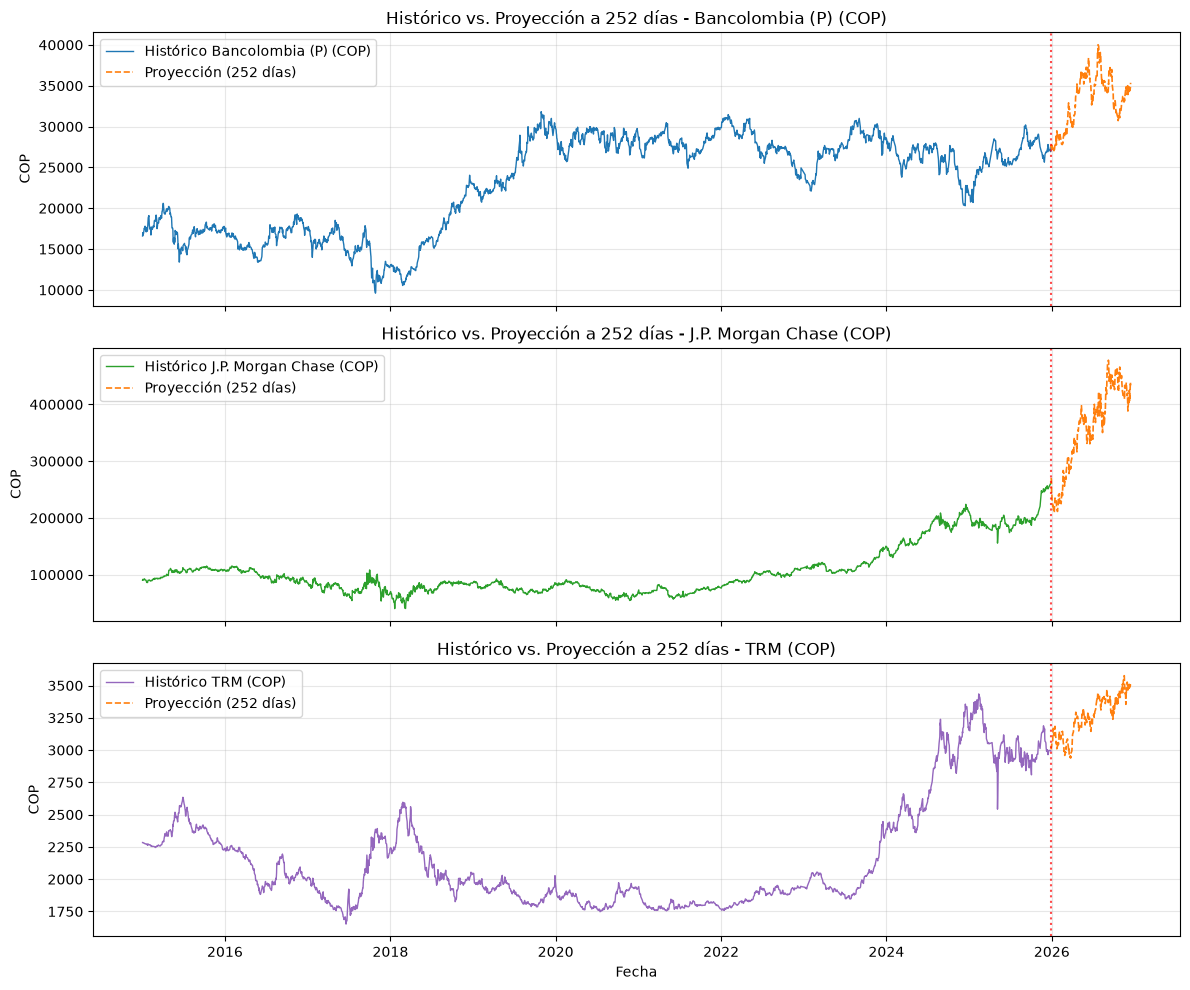

In [65]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
ultima_fecha = df_rendimiento.index[-1]

series_info = [
    ('Bancolombia (P) (COP)', 'Proy_Bancolombia (P) (COP)', '#1f77b4'),
    ('J.P. Morgan Chase (COP)', 'Proy_J.P. Morgan Chase (COP)', '#2ca02c'),
    ('TRM (COP)', 'Proy_TRM (COP)', '#9467bd')
]

for ax, (col_hist, col_proy, color) in zip(axes, series_info):
    # Serie histórica
    ax.plot(df_rendimiento.index, df_rendimiento[col_hist], label=f'Histórico {col_hist}', color=color, linewidth=1)
    # Serie proyectada
    ax.plot(df_proyecciones.index, df_proyecciones[col_proy], label='Proyección (252 días)', color='#ff7f0e', linestyle='--', linewidth=1.2)
    # Línea divisoria
    ax.axvline(ultima_fecha, color='red', linestyle=':', alpha=0.7)
    
    ax.set_title(f'Histórico vs. Proyección a 252 días - {col_hist}')
    ax.set_ylabel('COP')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

plt.xlabel('Fecha')
plt.tight_layout()
plt.show()

### **Simulación Montecarlos**